# DistilBERT local training and evaluation

The model trained on Apple M1 with MPS. This notebook displays the saved outputs of the training and evaluation scripts. Validation selected the checkpoint, scoring mode and alert threshold. WikiDetox supplies the original human-labeled test. The project assistant authored the attack and topic regression cases. Spoken dialogue and independent dialogue labels remain pending.

Completed 2 epochs on MPS, 5,350 optimizer updates
Elapsed: 116.5 minutes


,rows,attacks
fit,82513,9642
validation,9169,1071
test,22921,2679


,epoch,attack_precision,attack_recall,macro_f1
0,1,0.771136,0.843137,0.889222
1,2,0.844444,0.780579,0.893679


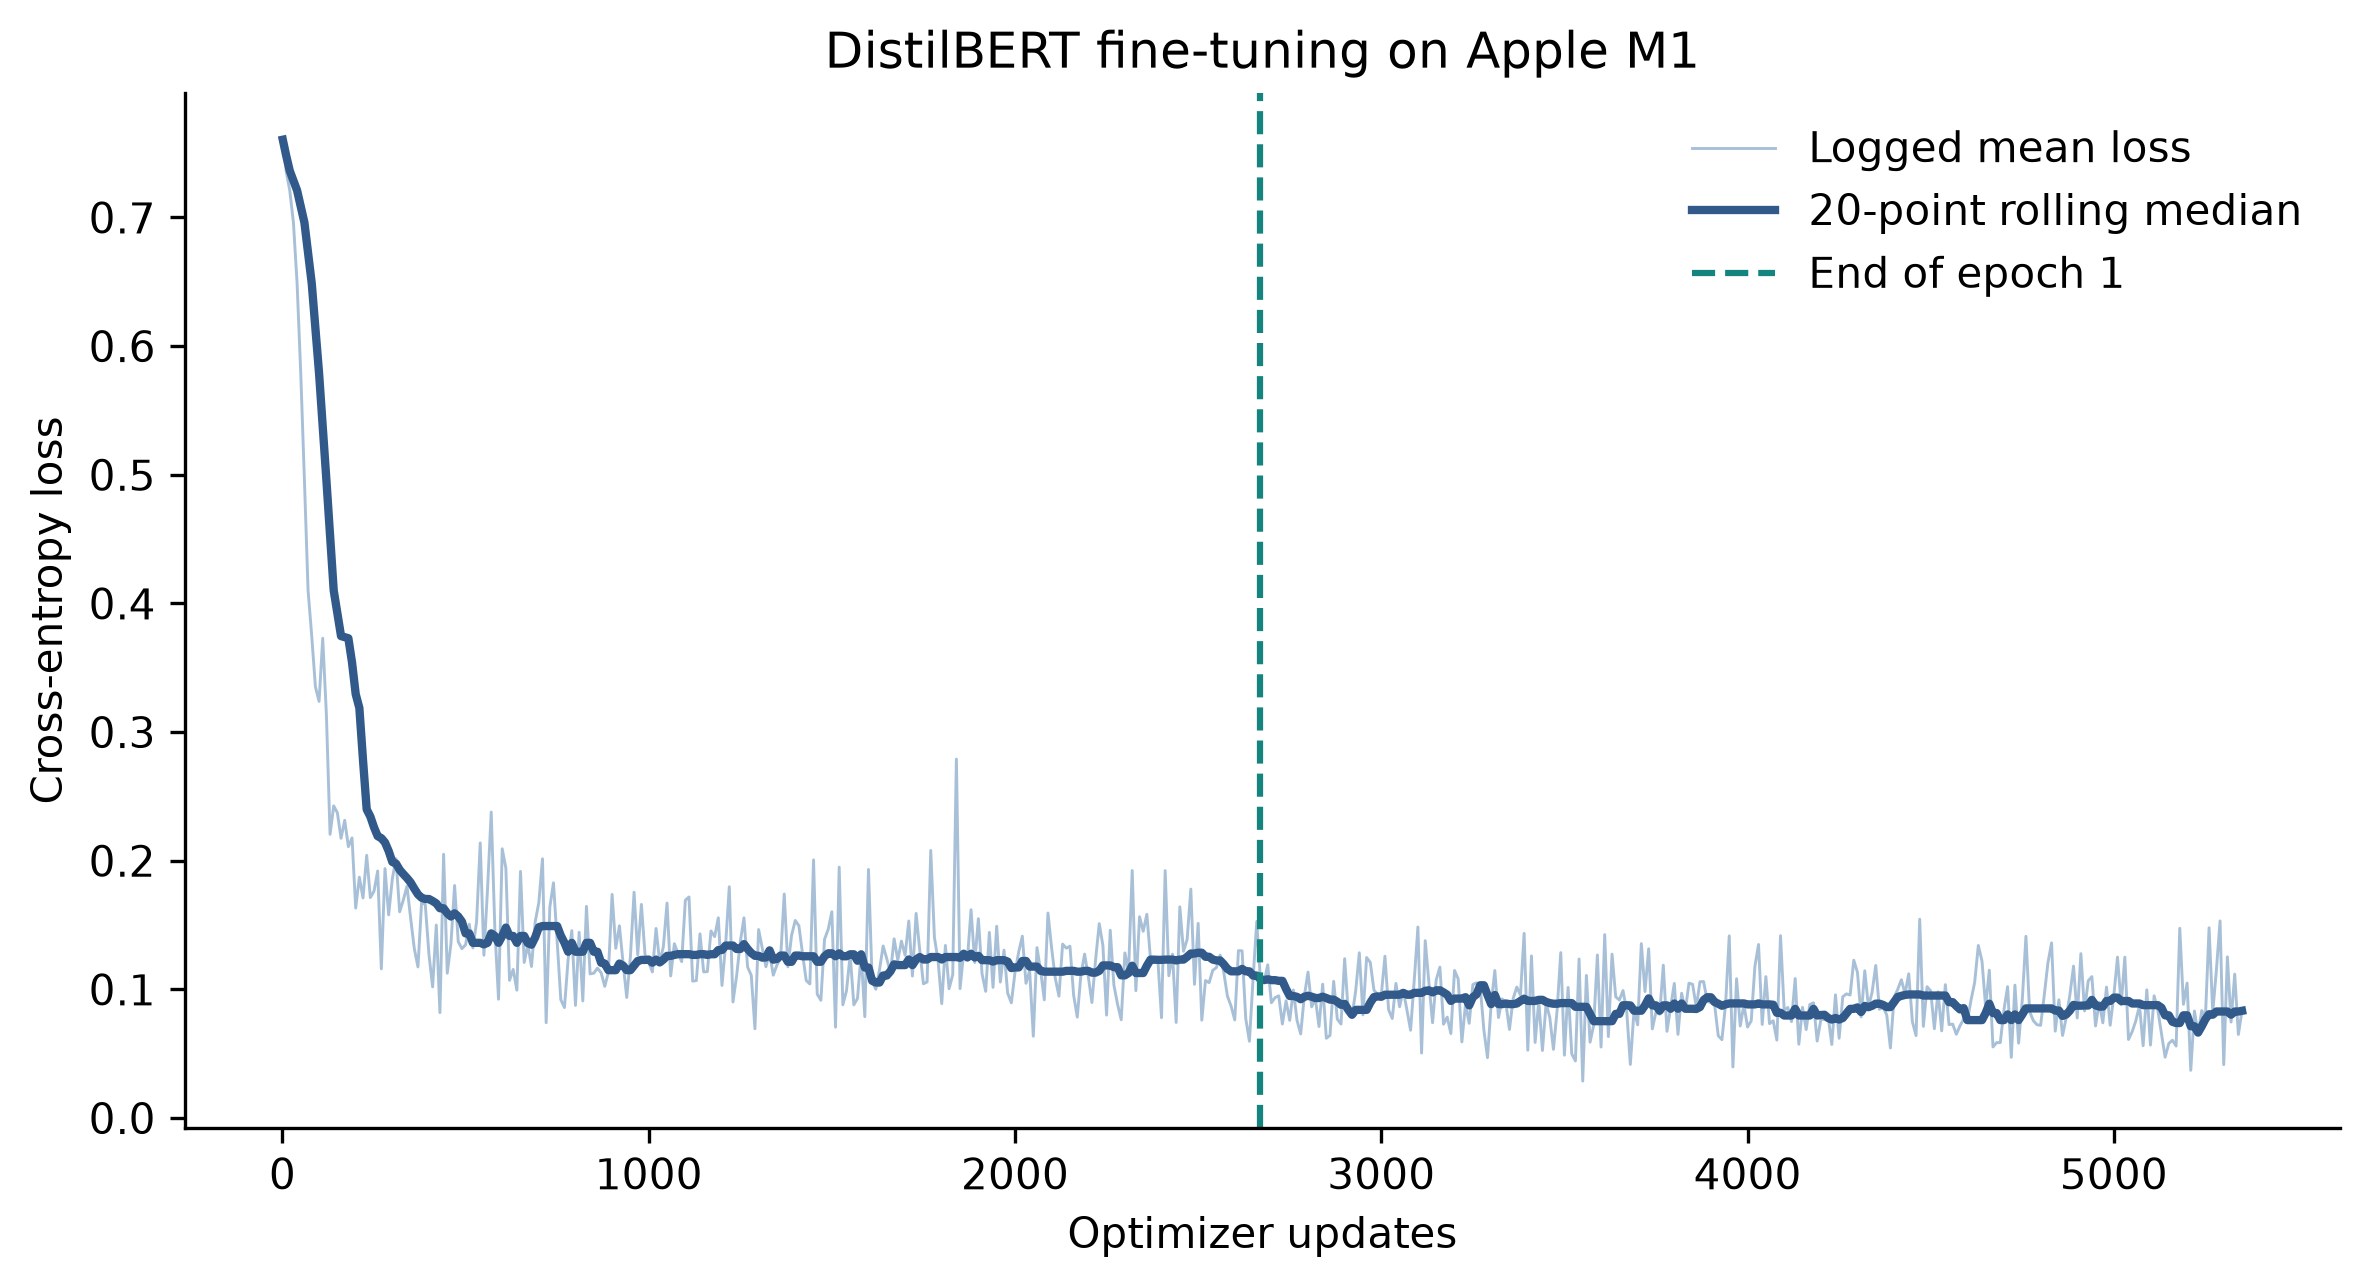

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / 'results/transformer').is_dir() else Path.cwd().parent
run = ROOT / 'results/transformer/distilbert_run02'
read = lambda path: json.loads(path.read_text())
config = read(run / 'configuration.json')
status = read(run / 'status.json')
summary = read(run / 'evaluation/summary.json')
topic = read(ROOT / 'results/contextual_topic/summary.json')
print(f"Completed {config['epochs']} epochs on {config['device'].upper()}, {status['updates']:,} optimizer updates")
print(f"Elapsed: {status['elapsed_seconds_this_process']/60:.1f} minutes")
display(pd.DataFrame(config['partitions']).T[['rows','attacks']])
display(pd.DataFrame(read(run / 'epoch_history.json'))[['epoch','attack_precision','attack_recall','macro_f1']])
display(Image(filename=str(ROOT / 'reports/figures/distilbert_training_loss.png'), width=850))

## Validation and original test

Selected whole scoring, threshold 0.30


,threshold,precision,recall,macro_f1
whole,0.3,0.801638,0.822596,0.893373
overlap,0.47,0.80112,0.80112,0.887409


,accuracy,attack_precision,attack_recall,macro_f1,brier,fp,fn
Current LinearSVC alert,0.9486,0.8037,0.7413,0.8712,0.0384,485.0,693.0
DistilBERT candidate,0.9536,0.7836,0.8328,0.8905,0.0347,616.0,448.0


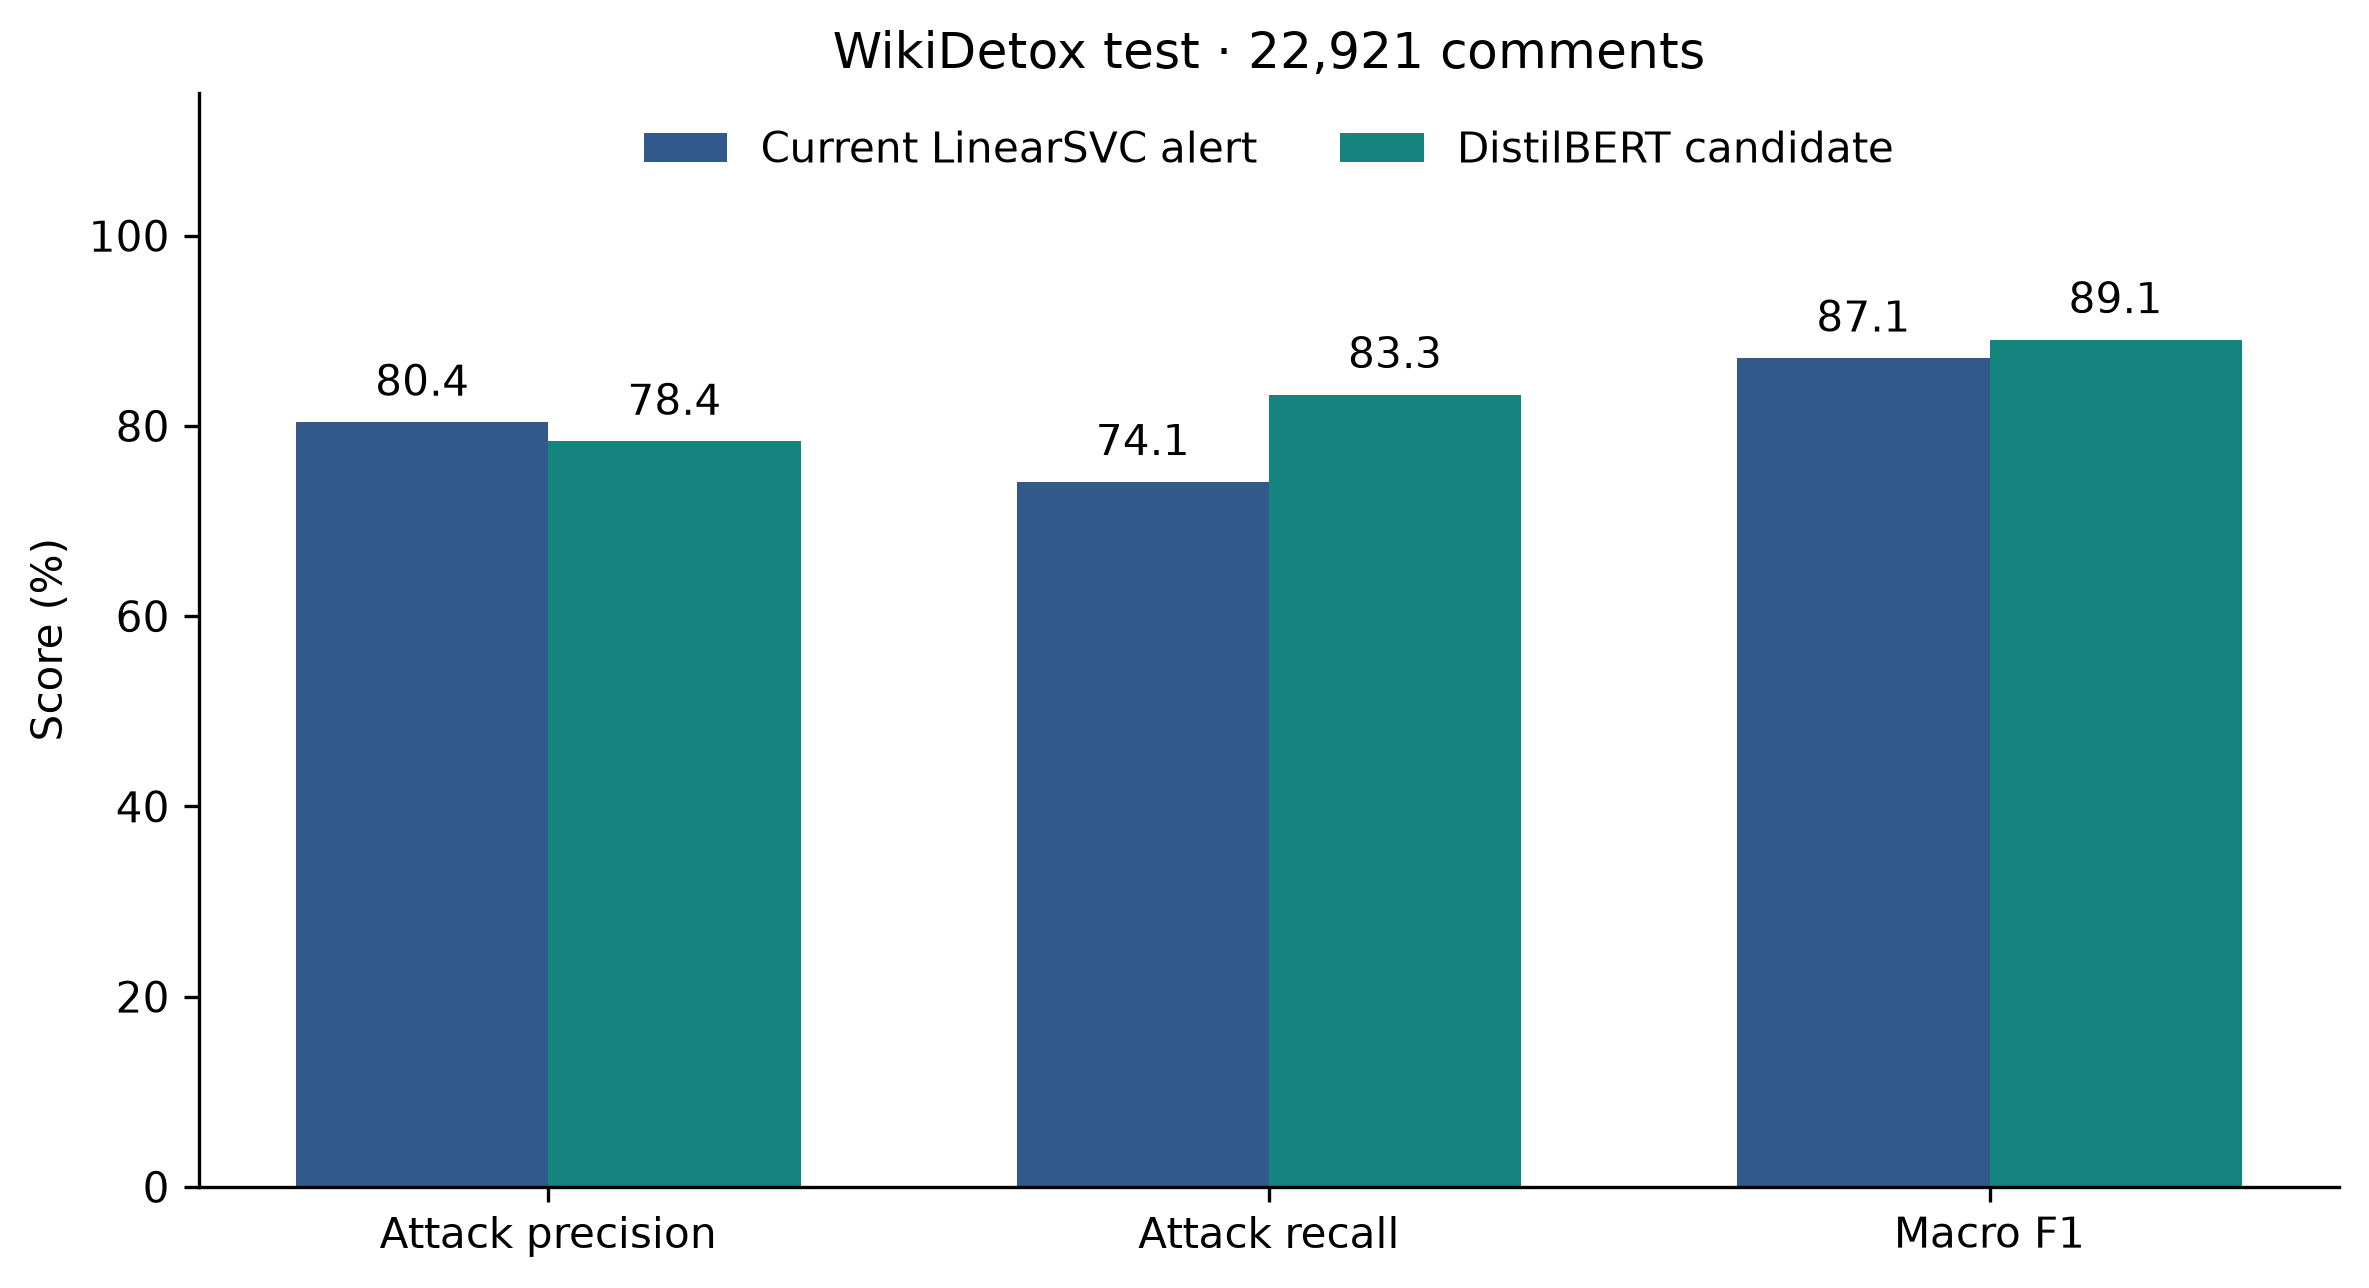

In [2]:
policy = summary['inference_policy']
print(f"Selected {policy['mode']} scoring, threshold {policy['threshold']:.2f}")
display(pd.DataFrame(policy['validation_options']).T[['threshold','precision','recall','macro_f1']])
columns = ['accuracy','attack_precision','attack_recall','macro_f1','brier','fp','fn']
display(pd.DataFrame(summary['wiki_test']).T[columns].round(4))
display(Image(filename=str(ROOT / 'reports/figures/distilbert_wikidetox_comparison.png'), width=850))

## Authored regression cases and local CPU timing

,accuracy,attack_precision,attack_recall,macro_f1,brier,fp,fn
Current LinearSVC alert,0.8036,0.8228,0.7738,0.8034,0.1564,14.0,19.0
DistilBERT candidate,0.9286,0.9390,0.9167,0.9286,0.0603,5.0,7.0


fp                       \
model                       Current LinearSVC alert DistilBERT candidate   
category                                                                   
boundaries_and_format                             3                    0   
claim_person_contrasts                            1                    0   
explicit_insult                                   0                    0   
impersonal_profanity                              2                    3   
long_mixed_turn                                   0                    0   
negation                                          4                    1   
obfuscation_typographical                         0                    0   
person_not_participant                            0                    0   
polite_surface                                    0                    0   
punctuation_free_disfluency                       0                    0   
quoted_reported_abuse                             4                    1   
respectful_disagreement                           0                    0   
slang_manglish                                    0                    0   
subtle_degradation                                0                    0   

                                                 fn                       
model                       Current LinearSVC alert DistilBERT candidate  
category                                                                  
boundaries_and_format                             0                    0  
claim_person_contrasts                            1                    1  
explicit_insult                                   2                    0  
impersonal_profanity                              0                    0  
long_mixed_turn                                   3                    0  
negation                                          2                    1  
obfuscation_typographical                         1                    2  
person_not_participant                            0                    0  
polite_surface                                    1                    0  
punctuation_free_disfluency                       1                    0  
quoted_reported_abuse                             0                    2  
respectful_disagreement                           0                    0  
slang_manglish                                    2                    0  
subtle_degradation                                6                    1

,median_ms,p95_ms,samples,device
Current LinearSVC alert,0.584979,0.78896,60,cpu
DistilBERT candidate,14.972792,19.553741,60,cpu


heldout_precision_at_least_80_percent      False
heldout_recall_improved                     True
heldout_macro_f1_improved                   True
regression_false_alerts_not_increased       True
regression_missed_attacks_not_increased     True
dtype: bool

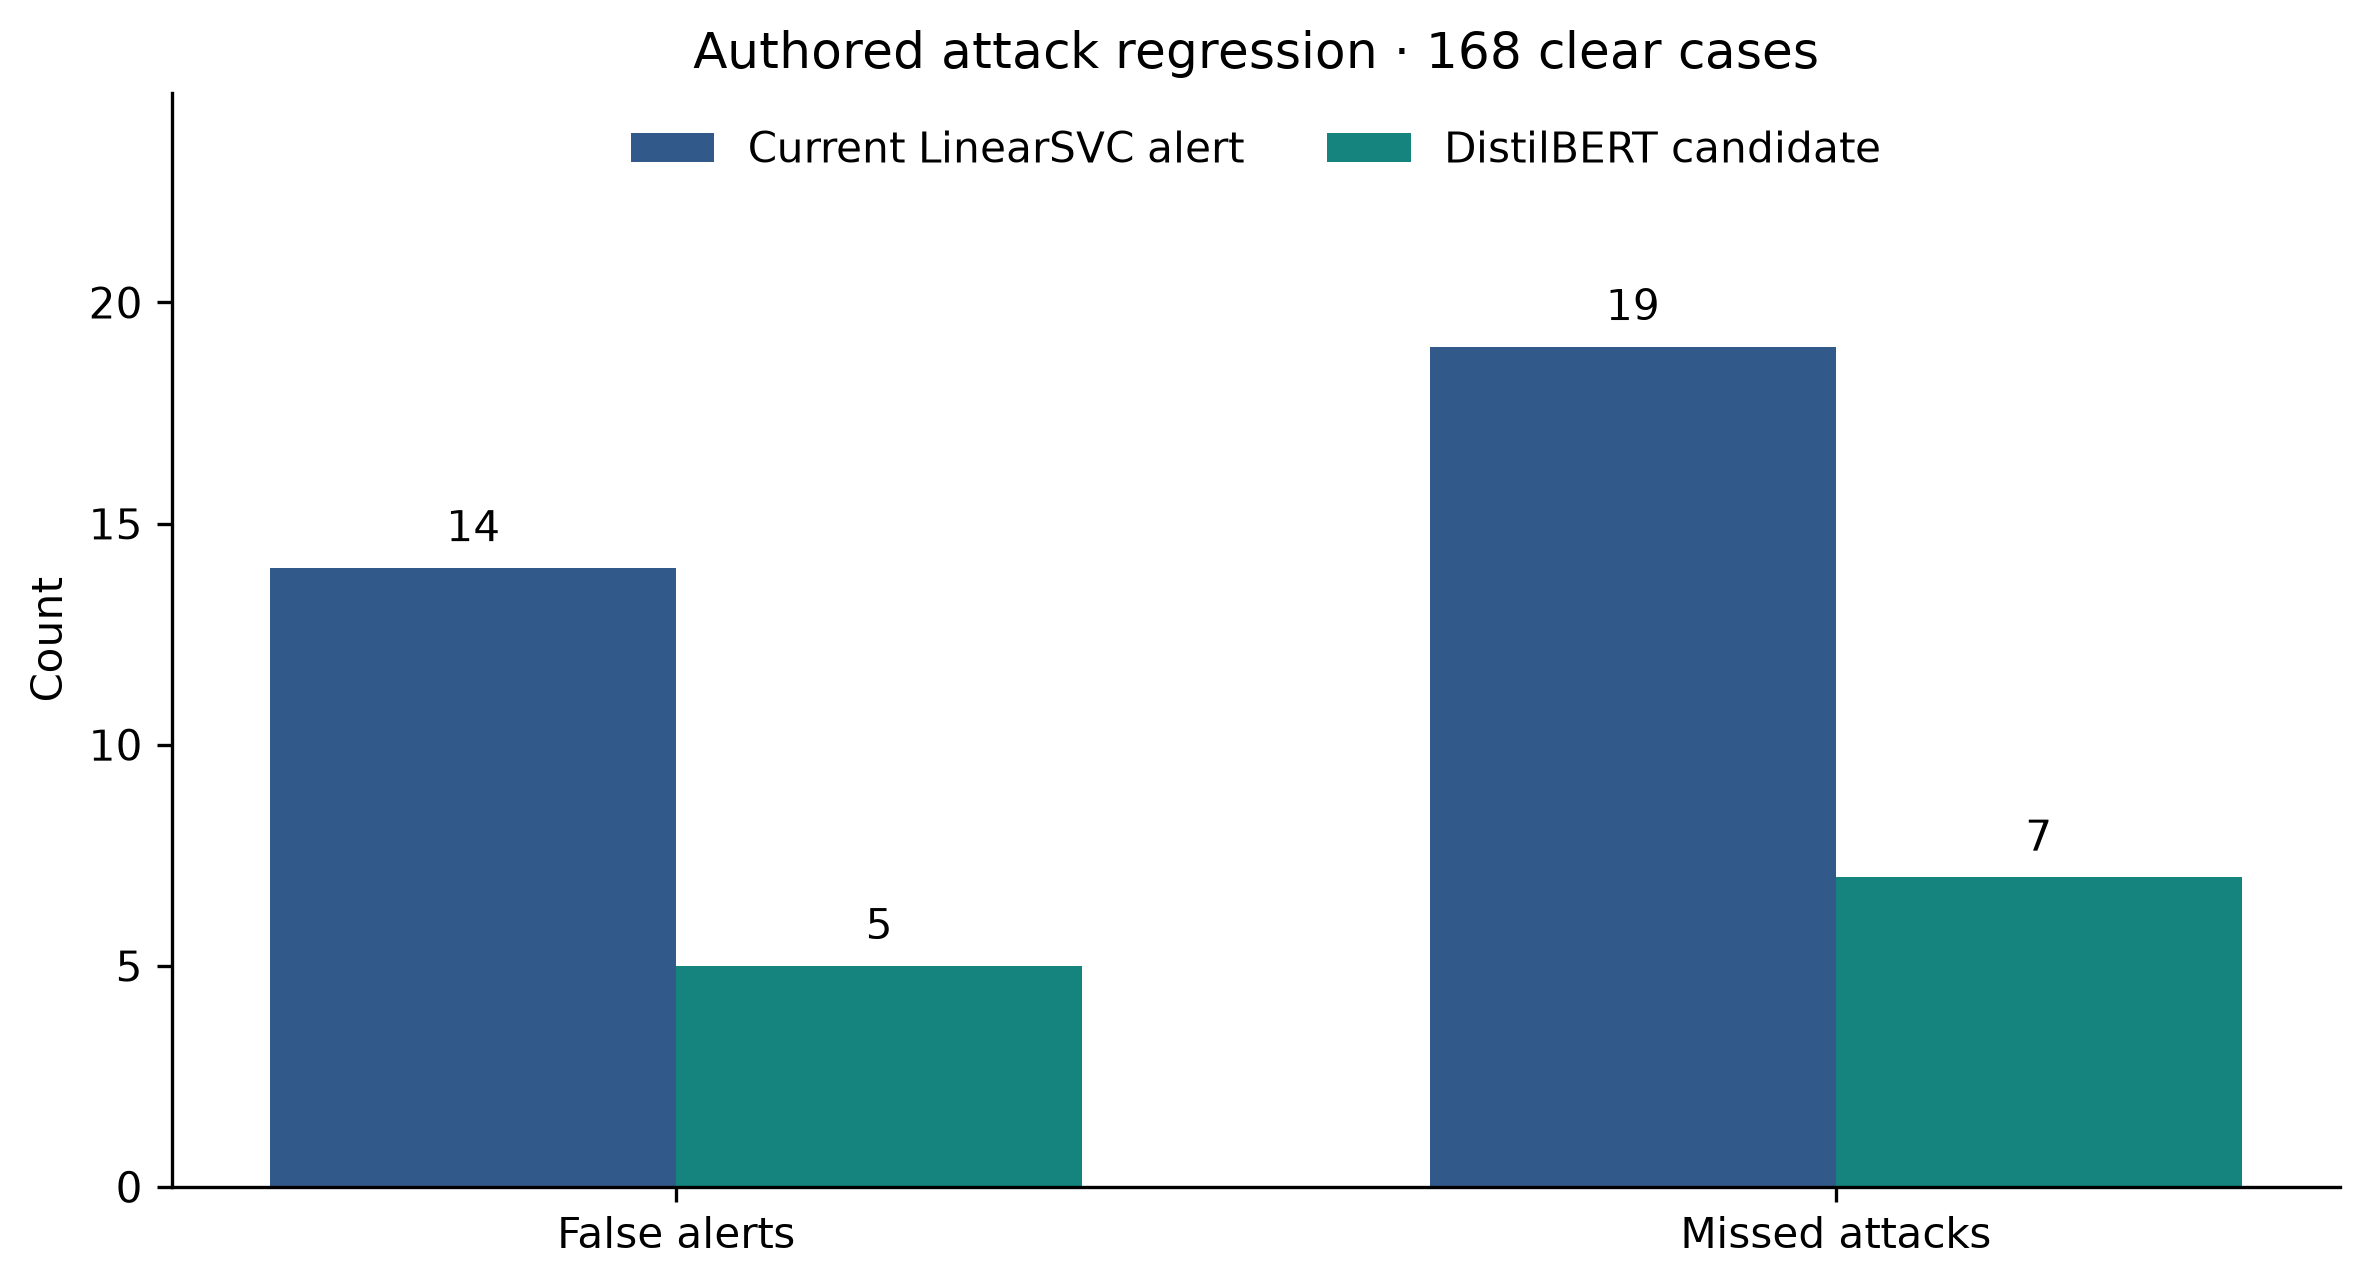

In [3]:
display(pd.DataFrame(summary['authored_regression']).T[columns].round(4))
categories = pd.read_csv(run / 'evaluation/stress_categories.csv')
display(categories.pivot(index='category', columns='model', values=['fp','fn']))
display(pd.DataFrame(summary['cpu_single_turn_latency']).T)
display(pd.Series(summary['adoption_checks']))
display(Image(filename=str(ROOT / 'reports/figures/distilbert_regression_errors.png'), width=850))

## Topic context comparison

{'threshold': 0.15000000000000002, 'context_window': 2, 'link_threshold': 0.15}
original_reserved


,events,detected,false_alerts,event_f1,turn_macro_f1
current,3.0,2.0,0.0,0.8,0.9479
candidate,3.0,2.0,0.0,0.8,0.9044


challenge


,events,detected,false_alerts,event_f1,turn_macro_f1
current,4.0,3.0,0.0,0.8571,0.9023
candidate,4.0,2.0,0.0,0.6667,0.8521


expanded_regression


,events,detected,false_alerts,event_f1,turn_macro_f1
current,18.0,17.0,2.0,0.9189,0.9164
candidate,18.0,16.0,1.0,0.9143,0.9356


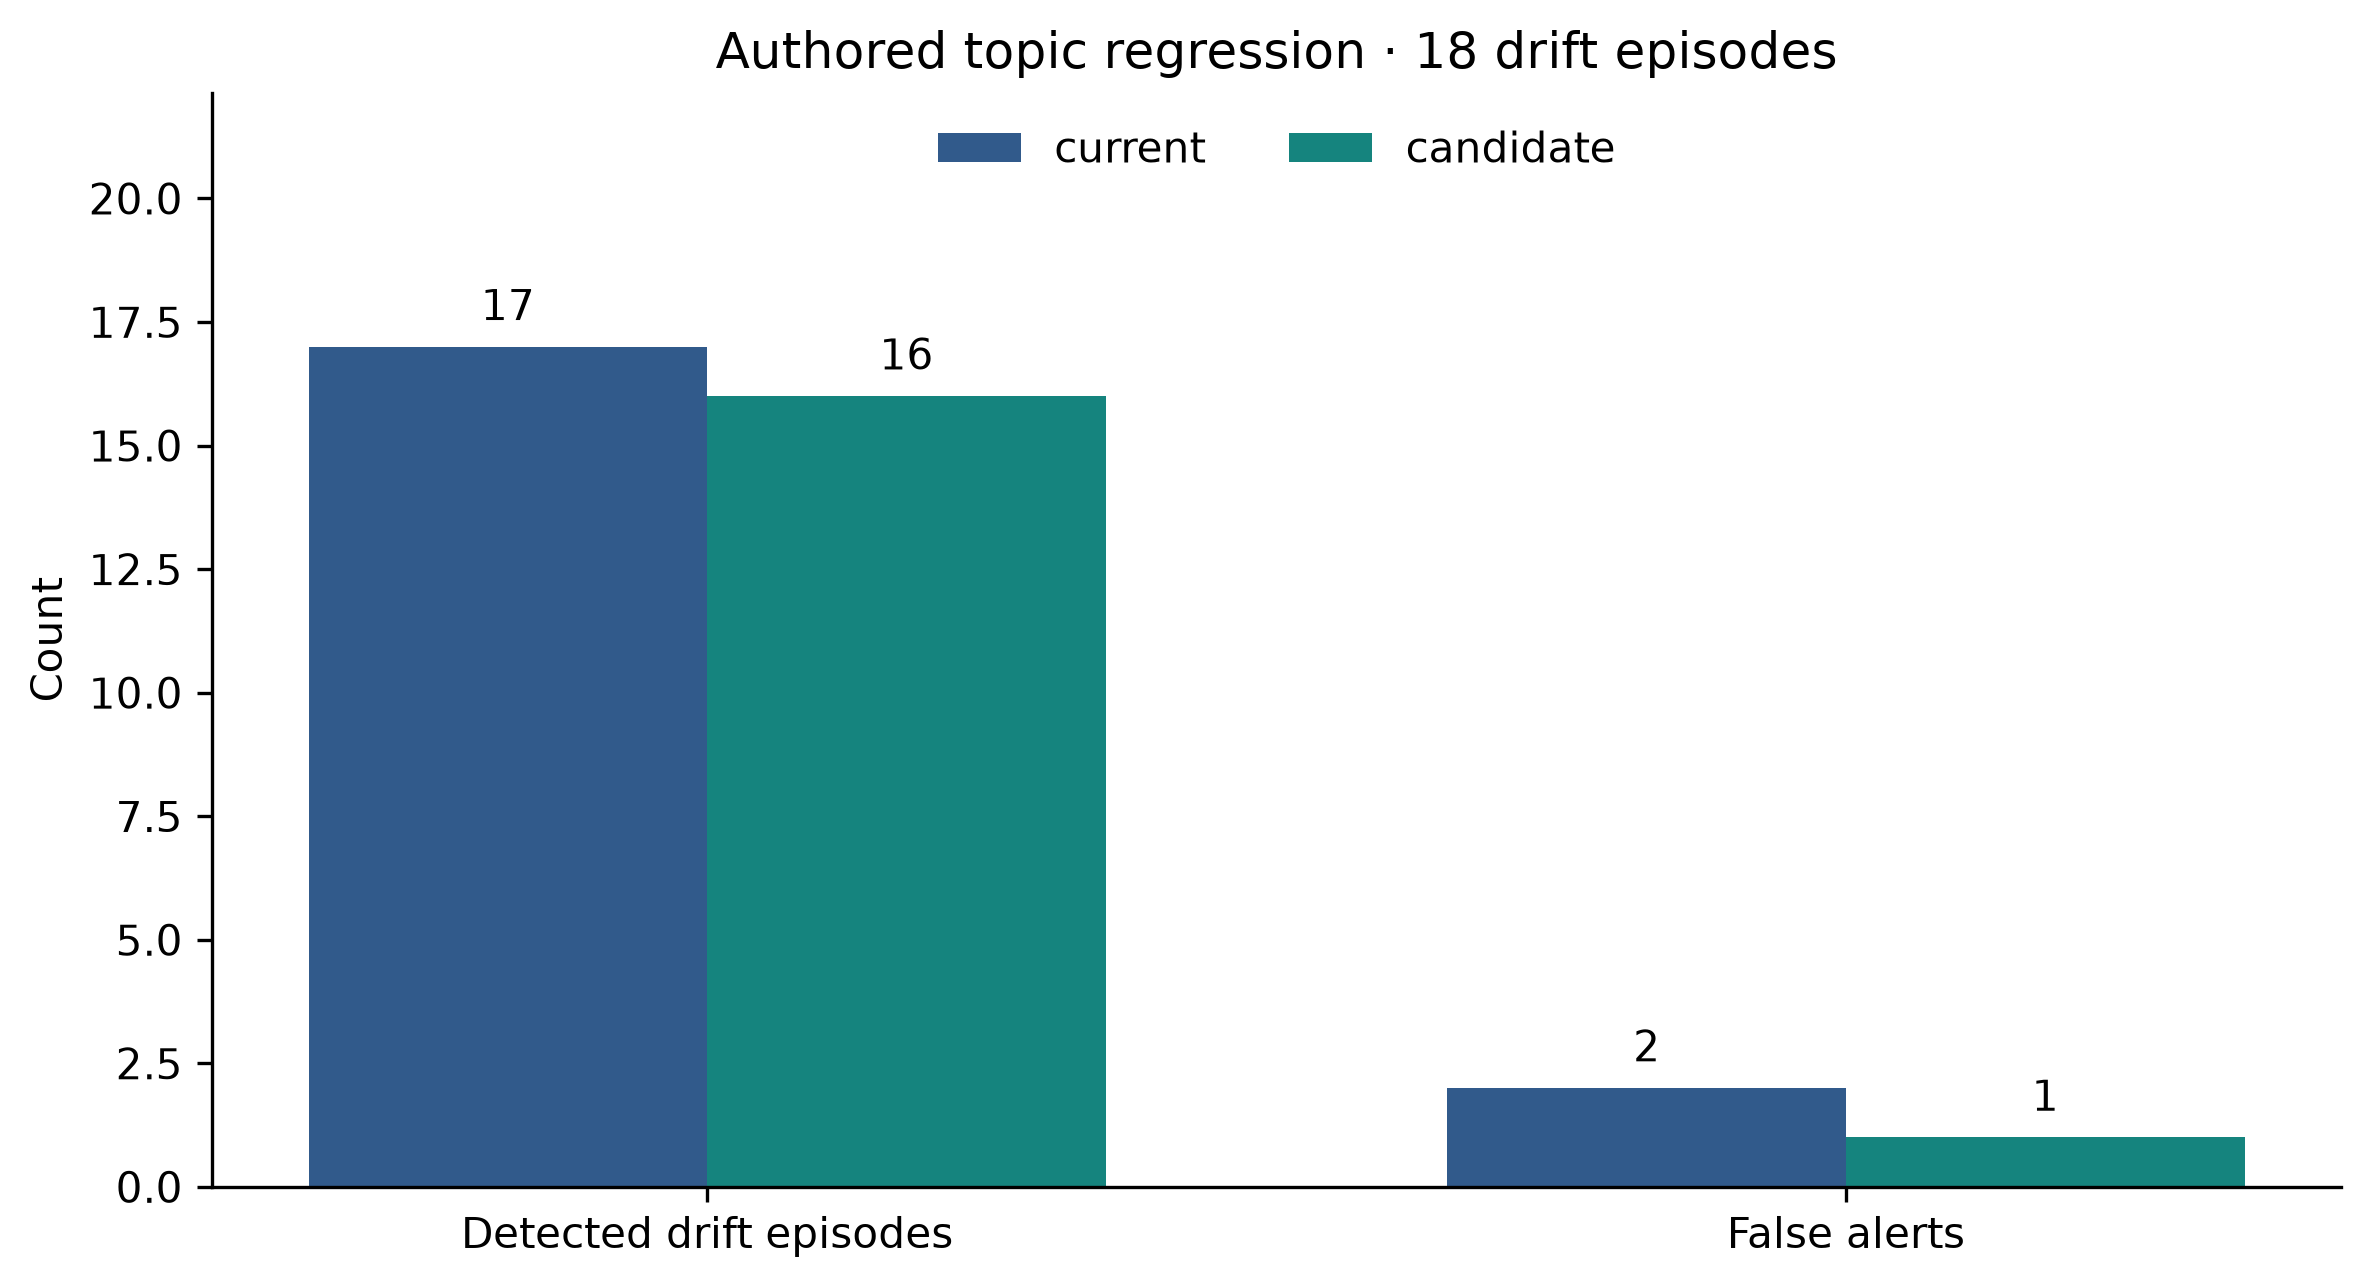

In [4]:
print(topic['policy']['settings'])
for partition in ('original_reserved','challenge','expanded_regression'):
    print(partition)
    display(pd.DataFrame(topic[partition]).T[['events','detected','false_alerts','event_f1','turn_macro_f1']].round(4))
display(Image(filename=str(ROOT / 'reports/figures/bounded_topic_comparison.png'), width=850))